# Clinical Decision Support
## Heart disease referral alerting

**Completed lab · UCI Cleveland dataset · Logistic regression**

This notebook contains the exercises, computed outputs, figures, and discussion answers. Run the cells in order with Python, pandas, NumPy, Matplotlib, seaborn and scikit-learn. A verified dataset snapshot is embedded for offline reruns.

| Test metric | Default cutoff 0.50 | Cost-based cutoff 1/6 |
|---|---:|---:|
| Accuracy | 81.97% | 78.69% |
| Sensitivity | 82.14% (23/28) | 100.00% (28/28) |
| Precision | 79.31% (23/29) | 68.29% (28/41) |
| Referral rate | 47.54% (29/61) | 67.21% (41/61) |
| Weighted error, `5 × FN + FP` | 31 | 13 |

The test ROC AUC is **0.9394**. These are results from one teaching split.

In [1]:
from io import BytesIO
import base64
import gzip
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 150)

## 1. Clinical scenario and dataset

The exercise models a referral alert from historical Cleveland records. The UCI data use 13 predictors and one angiographic outcome. We combine outcome codes 1–4 into the positive class and keep code 0 as the negative class.

The exercise uses all 13 lab features. A pre-referral workflow would require checking availability at the intended decision time. In particular, `ca` is a fluoroscopy-derived vessel count and could introduce leakage if it is obtained only during the workup that the alert is intended to trigger.

Dataset attribution: Janosi, Steinbrunn, Pfisterer and Detrano (1989), [Heart Disease, UCI Machine Learning Repository](https://doi.org/10.24432/C52P4X), CC BY 4.0. The [official processed Cleveland file](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data) was checked against the [lab mirror](https://raw.githubusercontent.com/AndreasPr/Heart-Disease-Prediction-System/master/processed.cleveland.data.csv) for the same parsed values and row order.

In [2]:
# Embedded original CSV so the notebook can run offline.
snapshot = """
H4sIAAAAAAACA5Vc23IjKwx8z7dsbaELl3na//+r4wxjUEvCyXnIbuIyhgGp1WoJN/lb/tD7R+vrX5b3a/z9fy2vf8v9l/yR
5/f2/f9X688b9fv/dr9ptPX212tlrI+v9yvy/LAbzPcQvuzg+6+5jna/8v1zj/qS9+B7qXIPWQv9/qHRn9/kNbOs37+XrWRn
mYOL2tc6vz/mr/4hGFyb3Zy5bGl25j7WX8MNbu/PvZ9Z78Ft2JlbWQPa3Kj3pn3VbgffM0tVO3N7H1x5DXYzi93tZ8PgmbWb
Z+bn3f0+qgqD57ILGkld50Frt+dR1R4G08V22bo3bM68LayCNc2ZL1h2lbVsWYPdUVkjgeNTNhv2/r3dz6waz7kJnDP8ZZ75
NTPbmW9rousyb6O2d6D6wWDbdb59wMy6ZvXnrMMum9Cr8KPeU5ij0njOgoP383I2c8Hd7tUONh8VBl922XNwQ6+i9VewbbUY
Np+ZwMd1v2N4I7HbMXebB9h2Y/uOONgZydDUn/3MtAfPDbsBjhGGNm7xmqbfYNBK9OcCziK81qaAnvpVi13IXDbBOZtdaacN
24NFAXo7J47xHFWLu81wzrR3oHncBhiagxdqoZGQ8apnMGwYTWvudsPIejwbx3jt9mWXnTlGJXPOZHC7uKOiG1KlABhs61I4
Z962LWtmkZoeld/tl4VdYCQzuGPEIANDDDCkGtFTEAA3ovkouYDVIAmfoqQ3Ejxnnm+Ho+Kyjqq6o8JwM42kg2PQCfRfG1Zh
w+4zrPDMy6u+AdBGyZeRUMBtVrHnvFgLGQt7jKTa4P44Rg3mWcxgWf6sBUhcWeEGd5scoZnn3CnglRTwYBOr1Nn2sjDzzGZ/
v1/rx1i1jG9jmEiB1Vxn2wb0vOdkN3hvX4WjegEgHNUEA4xVLMdwU0sCQwLmOQyGWfPUfc7bn5U6UKnu6CPtmSW4JF04mE18
/sR6y23p10iZgTUnY54nlyzrUYoDA4ckuo/qKimJ8zN7HiYYq+7XxhlJsiiJcxlmoGvmjA3dkXlzkrmJm7UgGNA2EjERQwJZ
Lw6G5mClGKtWUOUj6Ltlz/h8g34H86yWewpaGFkkmYMJbbsmG2YGO38u4FXq0bOsQKcNHIMj6EOUlJyH6XI/JmRD5I5KcMM2
ca33stViWC9HC3NGUqJBkhzzKjTPmXwPOGfdJG4AiTODt4XRgIhRLdY47qkRt4VT9LS43RH0dW2OcEzU5scr5BjPOfuZCYyk
mxQYl43oeT8fY4zQD8k3Cg51pcCUuCTDbsvM3J1a0SwArvSO3EmRA8+Zn+g4uHNbYDcpiQPPjfk7S+gH8PT7NWN7Q+Sl836V
ZL9g2UrOOg3+UYhzUkYwbcvV6ZDETthWMO1R3EmdsOAhgPDMtBO5AaYtXwpHdaMAu2Vb3uFmloB/3FBjkUTpmIPlikSfIWSP
D2kVkKExn1mDikcuoXsYM4ckVrgeErqQuGsS505HFYg+qng3bFew7drOyCuQhyaYTzUZ/C8e1IC8CNP2ZF6KOoeTqa5E2zH5
L8LIJtveIb2JoHo43dPZV13qGS+p1QGYTecQd5uTKgQZ3HrmKeoqDDbs2QsGTUJ85cqp3JrsNsfIXmtIYcnBX0/yX8K0nVNC
4oKzy8gQ/oypNhcu0Kdk4ggd0vZxgr/5zFMYgg0bZ7dABKMZIgH+Rj0OFlTSBsAOg/SYHBXq0+O2bSSe1zHB6OBV86hW3Nxh
IB+sgJ0ZCYNTZ3CMCjhZ5rJR22lnofeK4jbG48YH82Qn9E7bxgpILQ4Mtm03SghJCRkZGR61ZxZ0jBEFQLVCrxPDgObr5MuA
2ovjkVPSaGvyhlSg+Gsysu2SD2vlxDwBei+7A1hKUAT92wiUwMJaEtofMOAI+lANuLrbr73ZbpK6qicoKuWrRplDt7ZNgagn
7lxDnKMBM49zoSupGIkUeBQ2lJcw2tSoPGK5ibfFDL9hI8naW8pm7HqemSXAtqJ1rnVoENJQFyoFkLcsBucz2Af/atQ8CbBg
HVw12rbbMNqUZEAQMUUfdX6B3PiJ7VhJOIfnhW4zSM0aBhJwawmCcU4/RNgppLVDjiBpiY2xknCmYUiGpjqDsN3k56zdFEBc
atMTGtZRI/kefBcjmeGYMak0j1y+OKlzQemZC39mns7AGgVeQGdRfdNlBmWnOCBJTbsghFUUW8lZ5x7co8rhaARXU+gX1Es5
qbChknnSV2TinxNnUPKUU1pEDgueSAWMxIiB/pkrhrRp2sD/mh6Pql4WC/r2yIxIsV82btgNJKXaucaZwrWoHTouJJRUUnui
yJe5YSUgLzkU6kkqeLMwVjDPyudaAPahTB0NToA/FE8oFhKwlaRfP7NtNpwXjuoThEEZ9nZ8oZGW2yPnRS5Up6g+QLUcBwr3
lOcWeN4zcwMfN1Ev5HMdqPr3sNpORW9/zhgkn5ahK+Swb3UGyzYtiq2slv9dzai8VtkWh0KTzmBSVS7nzrINLEFeV2ATAySU
+4UapwK/6OSO2WiHJZlZUgMjJ1qyk4UmzcfspPowtUOVAuO6k9ddbPopL+o9eWa0EZ8XvXdbnSD/9HPo/21P0E3hUGxldjud
dM/IJhUVwLPX5KgE+3Z2gsGlhwIb/aJjaPI/xvDsUeifJTPY9uEIXL0SQmJShH1QLZYgajss2vNOSpQzGUlm42jB1qadlk87
lF0usruONIb+Ai/ypkn7MpGbirBeKcsvoXKStPCJ60jrCe66+GoKPsTh+KxQ8a4EqO9s4CXyvpc9xkHMIiejzfAq0JtgCC9B
Mldczj6zPuxyKjsMkmup0FizFhRmTX/V9XPBmxGXQhOenGQ0hf1CAldiG0mD1FnvNDJqM/QsG3FXITbrJDOYj3n1j0/sb8T6
he60noEuFy9aDijBsuv48TSqSazhXfUjE+LY8WNSKoU0/VLzzG7ZcKYNA3uBjp9iZp2dmijgXbw6+LYqVBMa9cTXWHbxfbHt
IB2yK/LP3O5qv81BM04B7I+307ITLbFFamK+QieIgbDpkv/eT8yx+HFBMlKacUjXtD2SzkFKiy5kfCorwBZkUdhcUIxPyW7B
W27RtsZBUOIv5okJabov+LTQE0F58ltC69n2Zo9g9DGXm8vusaHikNeAN1NinPX6nMutwSMp69UPKWjSg8xABLq4muBmjk1j
7RelBpGkoNiT5j/XzFuOCNaT4scNSYKorT3BkQfykyaSegVlzQrERghDnr61tH3Ozdm2CTY16X6GdLfWXwphNTHPanuckM1I
T/y5/lKCkwHNQklJcWw3HK4RDtNuQZLP0I7GsVsSovOMkQzkGvTUQ21Ok87Bz2m3qV+QkZQkJDYWPQumVEiatvr3U+u0tohh
KgcMKxnx9K1ZEoKNJ56SFLnmzP23rQmKhT2OV146n2Eo1p0Zm7ZbP5vnZf6cEc7l7Nfn5oKNBQJp0V3vqc62ThWIZ9FXSOV8
r9DjkOACT2UOzNHcnemnfgpj2WhfRlKjrD1q91ZxFAuCcdKhDY6S6whlOOPc0gw2RcxlJ1kRmWXv/tCKlbkGHMw3EdNJ17Yx
stsnpG462exgdlXnWY3UK0C+ZflbUcJEhDH7na+RYSTJbmNbl+suaPLLo5qFACyi0q6DsmNhLhVMbssUK4QdWv+sfHeFezol
6cyiL3zj7KhA3azxUWvQpIpw1ePgBMHclSp3BUN+hr9tEFJ+myLolTSU/bbG1aCVd24YXv4w8k2Dc2YnTTPeIShvpfUwcXKx
UyyQdDoIcOw4WClx0UZ0JNdP4eAPb6BtPIXjjL0FpjGB+HhxjvLuUFt0GaEEVD5zbYudlNZQbU7Vkm7H28MYawiQ/rseEo2M
Fy3KVI5QUvJ9cM6n/E2G9vGKD9XIRwYdVTTlOHO5jlczD9ULXamuE1p1n7o4kaO3kNnQhfGimVTwIHhuWdV1tar8bCRsLiNg
+x65ZRvsREF9Ukdsa7jMYMydsS5+B1ihK7104lUh+Wol3vdzlwX3sq+PvaWcXCJr18/wZ3pf8PYG16Q/alYg8Pra88w1LVnb
OmjbjMR5Fd4nqFl/1L/vodjItr15XyHbvIH9jeUS9WHOfSqR8mN7qOvcreWXe/3cDweablLFyytwLVYEeYTB728gIGzqamFm
QbWAy6Evn3fP4eadhHUAruc60xXDa9EDpUCNl9yN5Vnh557e3Yil8oYgdB9+H4cLPsV5MyRF7zpTOdbZ+QMIVU1ujeg5cx6B
zGzsLE7Aa6eZd4x012ChzsA5L5DTLbBPmWANXa1cqn1CaIo7NKDswqP77oMP/bTOq0bsGwxKmOktBV5wCyu7t4CAkehzR0d2
pQmOqu/LqBQ6PO29pIYzb5B1FmZYvhpp2n+3hmDXDB/5bj9+MQeGGogWknNWk/xiCmrgLzS+1JCrCoZXc+39eIHC9Ci5K01q
9log1LT4xRz7i0+wm1YdaWWnU7AmDtmOZVBMirg4vvdZE0JBaYJht8d3eTbxNi//LSgz1uBVBJZEyjcFa/dNEQhZwoemGdrd
FFvindIfBQom7isX2DcHeLx7k+D8ZjneiZESyxcAI5jYyAidBa6LIdRQ350F/wGGxfShHUgAAA==
"""
raw_csv = gzip.decompress(base64.b64decode(snapshot))
assert hashlib.sha256(raw_csv).hexdigest() == "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8"
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target",
]
df = pd.read_csv(BytesIO(raw_csv), names=columns, na_values="?")
assert df.shape == (303, 14) and df.target.isin([0, 1, 2, 3, 4]).all()
df["target"] = df.target.gt(0).astype(int)
print(f"Patients: {len(df)} | Predictor columns: {df.shape[1] - 1}")
display(df.head())

Patients: 303 | Predictor columns: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Exploratory data analysis
### 2.1 Missing values

`ca` has four missing values and `thal` has two. An arithmetic mean can yield a fractional vessel count or a number that corresponds to no valid defect category. Mode imputation uses an observed count or category. The full-data modes below are for descriptive EDA. The modeling section estimates its modes from the training rows.

In [3]:
affected = ["ca", "thal"]
eda_modes = df[affected].mode().iloc[0]
df_imputed = df.fillna(eda_modes)
display(pd.DataFrame({
    "Missing before": df.isna().sum(),
    "Missing after": df_imputed.isna().sum(),
}))
display(eda_modes.astype(int).rename("Imputed code").to_frame())
assert df_imputed.isna().sum().sum() == 0

,Missing before,Missing after
age,0,0
sex,0,0
cp,0,0
trestbps,0,0
chol,0,0
fbs,0,0
restecg,0,0
thalach,0,0
exang,0,0
oldpeak,0,0


,Imputed code
ca,0
thal,3


### 2.2 Encode categorical features

One-hot encode `cp`, `restecg`, `slope` and `thal`, dropping one reference level per feature to match the lab's example profiles. The reference levels are `cp=1`, `restecg=0`, `slope=1` and `thal=3`. Keep the binary flags and vessel count as numeric columns. Explicit levels keep the encoding consistent across the train, test and example patients.

In [4]:
category_levels = {
    "cp": [1, 2, 3, 4],
    "restecg": [0, 1, 2],
    "slope": [1, 2, 3],
    "thal": [3, 6, 7],
}
integer_cols = [*category_levels, "sex", "fbs", "exang", "ca"]

def encode_features(frame):
    encoded = frame.astype({name: int for name in integer_cols})
    for name, levels in category_levels.items():
        assert encoded[name].isin(levels).all(), name
        encoded[name] = pd.Categorical(encoded[name], categories=levels)
    return pd.get_dummies(encoded, columns=list(category_levels), drop_first=True, dtype=int)

df_encoded = encode_features(df_imputed)
print(f"Columns including target: {df.shape[1]} before encoding, {df_encoded.shape[1]} after")
display(df_encoded.head())

Columns including target: 14 before encoding, 19 after


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6,thal_7
0,63.0,1,145.0,233.0,1,150.0,0,2.3,0,0,0,0,0,0,1,0,1,1,0
1,67.0,1,160.0,286.0,0,108.0,1,1.5,3,1,0,0,1,0,1,1,0,0,0
2,67.0,1,120.0,229.0,0,129.0,1,2.6,2,1,0,0,1,0,1,1,0,0,1
3,37.0,1,130.0,250.0,0,187.0,0,3.5,0,0,0,1,0,0,0,0,1,0,0
4,41.0,0,130.0,204.0,0,172.0,0,1.4,0,0,1,0,0,0,1,0,0,0,0


### 2.3 Target distribution

,Count,Proportion (%)
target,,
0,164,54.13
1,139,45.87


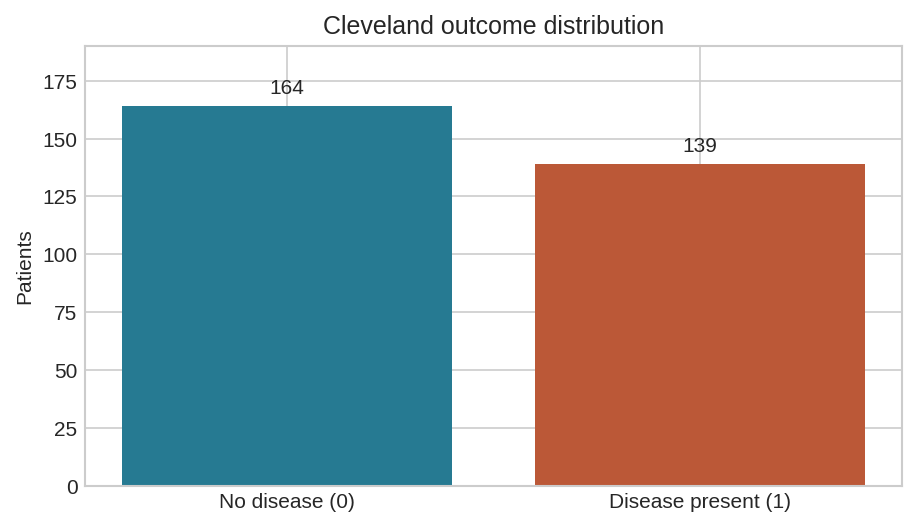

In [5]:
class_counts = df_encoded.target.value_counts().sort_index()
class_summary = pd.DataFrame({"Count": class_counts, "Proportion (%)": class_counts / len(df_encoded) * 100})
display(class_summary.round(2))
fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
bars = ax.bar(["No disease (0)", "Disease present (1)"], class_counts, color=["#267a92", "#bb5837"])
ax.bar_label(bars, padding=4)
ax.set(title="Cleveland outcome distribution", ylabel="Patients", ylim=(0, 190))
plt.show()

The Cleveland split is **54.13% negative and 45.87% positive**, closer to even than the diabetes lab's roughly **65% negative and 35% positive**. Predicting the majority class for every Cleveland record would score about 54% accuracy on the full dataset. Sensitivity and referral rate remain important because the two errors have different costs in this lab.

### 2.4 Continuous feature distributions

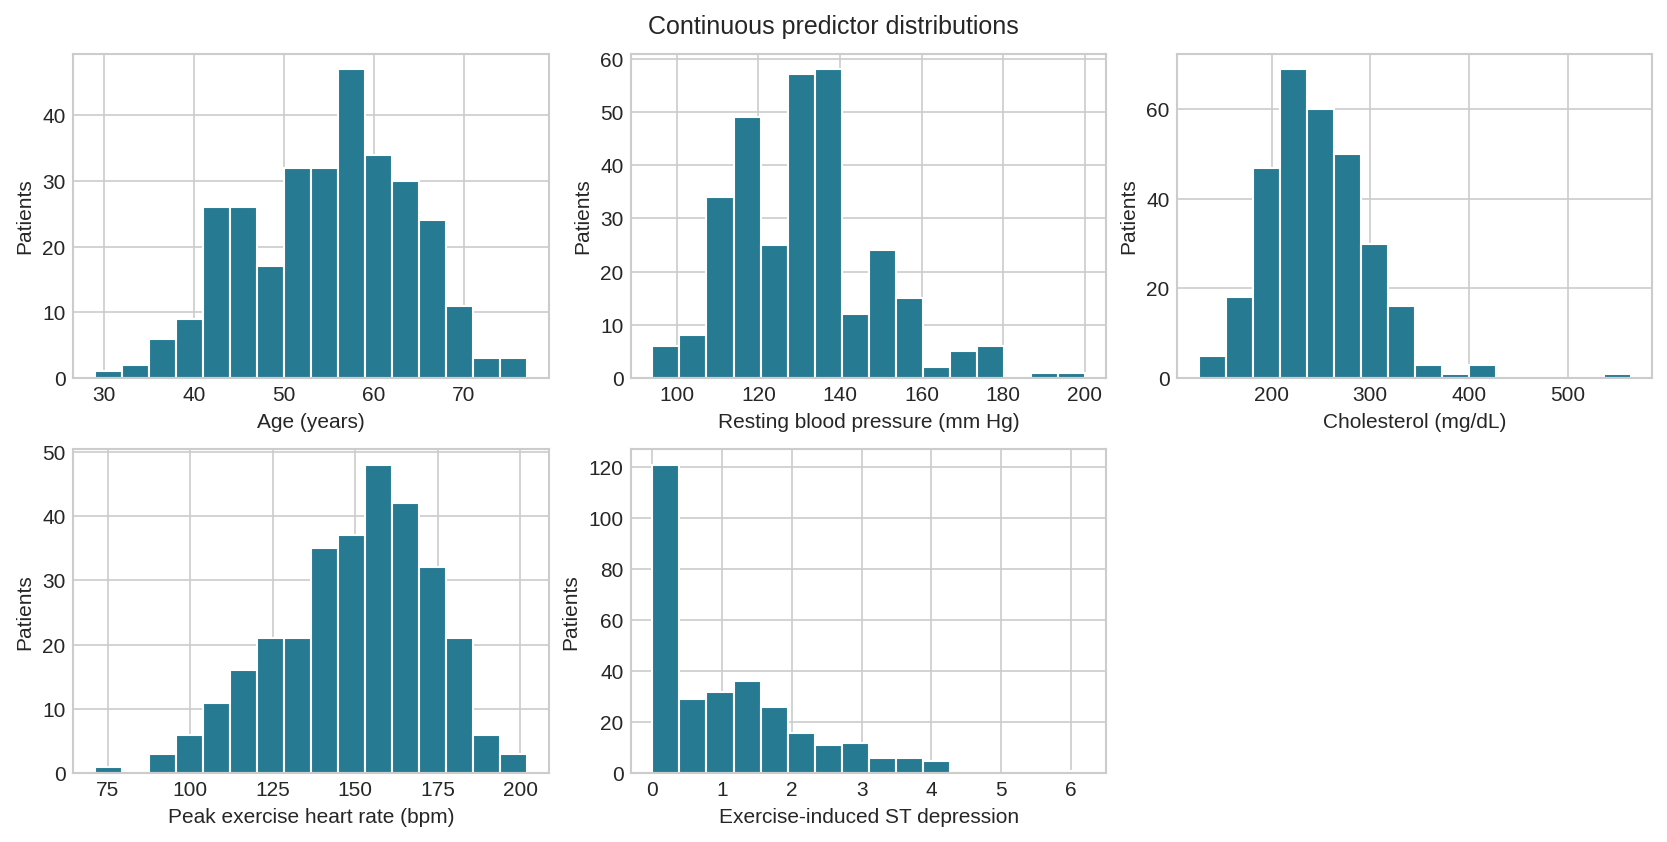

In [6]:
continuous = {
    "age": "Age (years)", "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Cholesterol (mg/dL)", "thalach": "Peak exercise heart rate (bpm)",
    "oldpeak": "Exercise-induced ST depression",
}
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), layout="constrained")
for ax, (feature, label) in zip(axes.flat, continuous.items()):
    ax.hist(df_encoded[feature], bins=16, color="#267a92", edgecolor="white")
    ax.set(xlabel=label, ylabel="Patients")
axes.flat[-1].axis("off")
fig.suptitle("Continuous predictor distributions")
plt.show()

### 2.5 Outliers

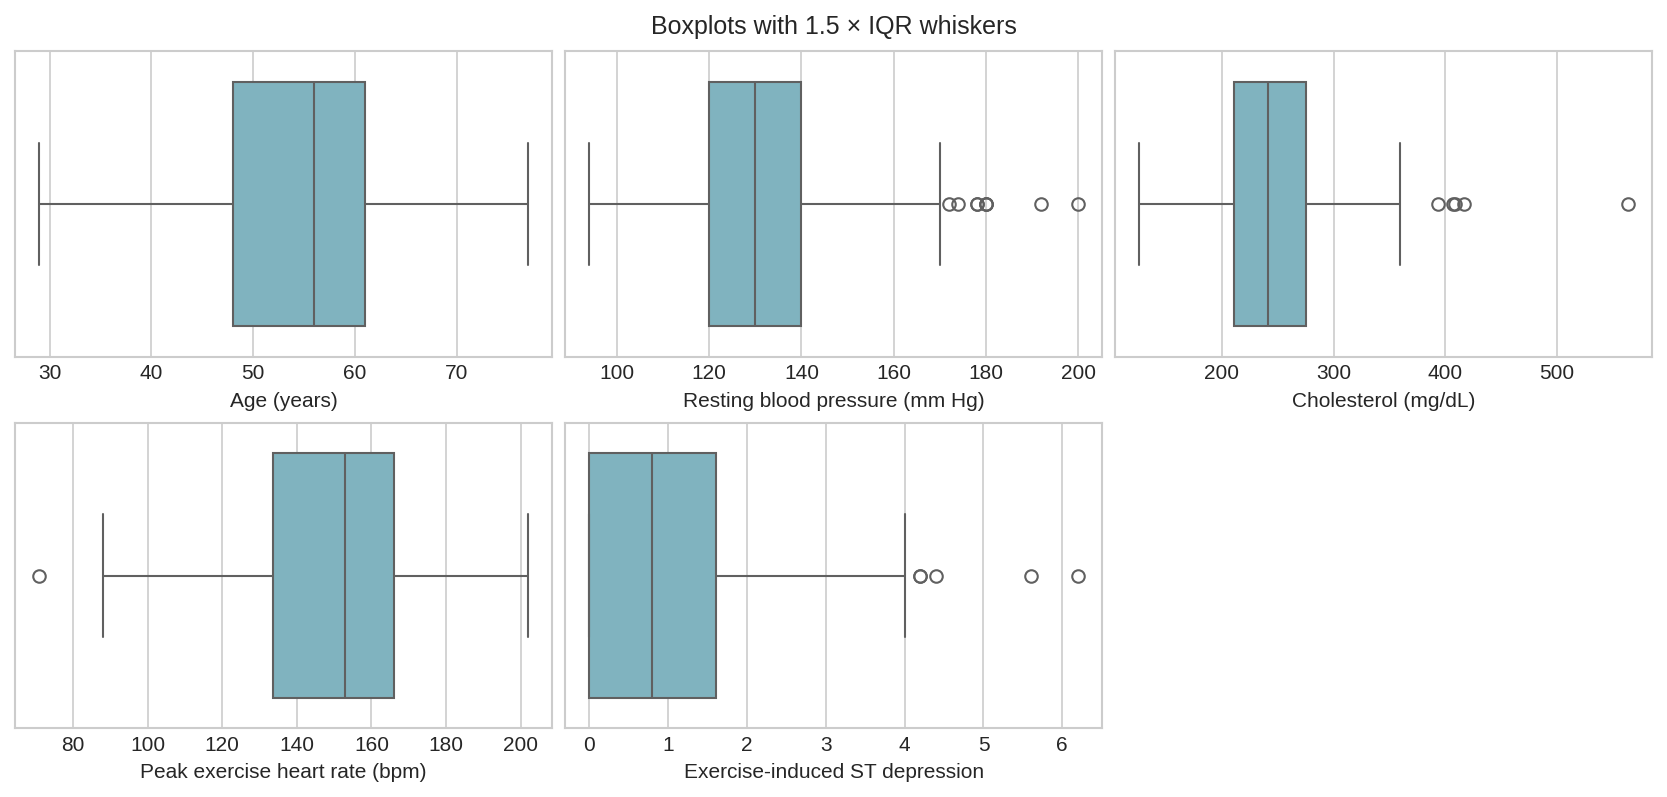

,Feature,Flagged,Minimum flagged,Maximum flagged
0,age,0,NaN,NaN
1,trestbps,9,172.0,200.0
2,chol,5,394.0,564.0
3,thalach,1,71.0,71.0
4,oldpeak,5,4.2,6.2


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), layout="constrained")
outlier_rows = []
for ax, (feature, label) in zip(axes.flat, continuous.items()):
    values = df_encoded[feature]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = values[(values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)]
    outlier_rows.append((feature, len(flagged), flagged.min(), flagged.max()))
    sns.boxplot(x=values, ax=ax, whis=1.5, color="#76bac9")
    ax.set(xlabel=label)
axes.flat[-1].axis("off")
fig.suptitle("Boxplots with 1.5 × IQR whiskers")
plt.show()
display(pd.DataFrame(outlier_rows, columns=["Feature", "Flagged", "Minimum flagged", "Maximum flagged"]))

The boxplots flag nine high blood-pressure readings (172–200 mm Hg), five high cholesterol values (394–564 mg/dL), one low peak heart rate (71 bpm), and five high `oldpeak` values (4.2–6.2). Age has no flags. All rows are retained because the IQR rule identifies unusual values without determining whether they are data errors.

### 2.6 Correlations

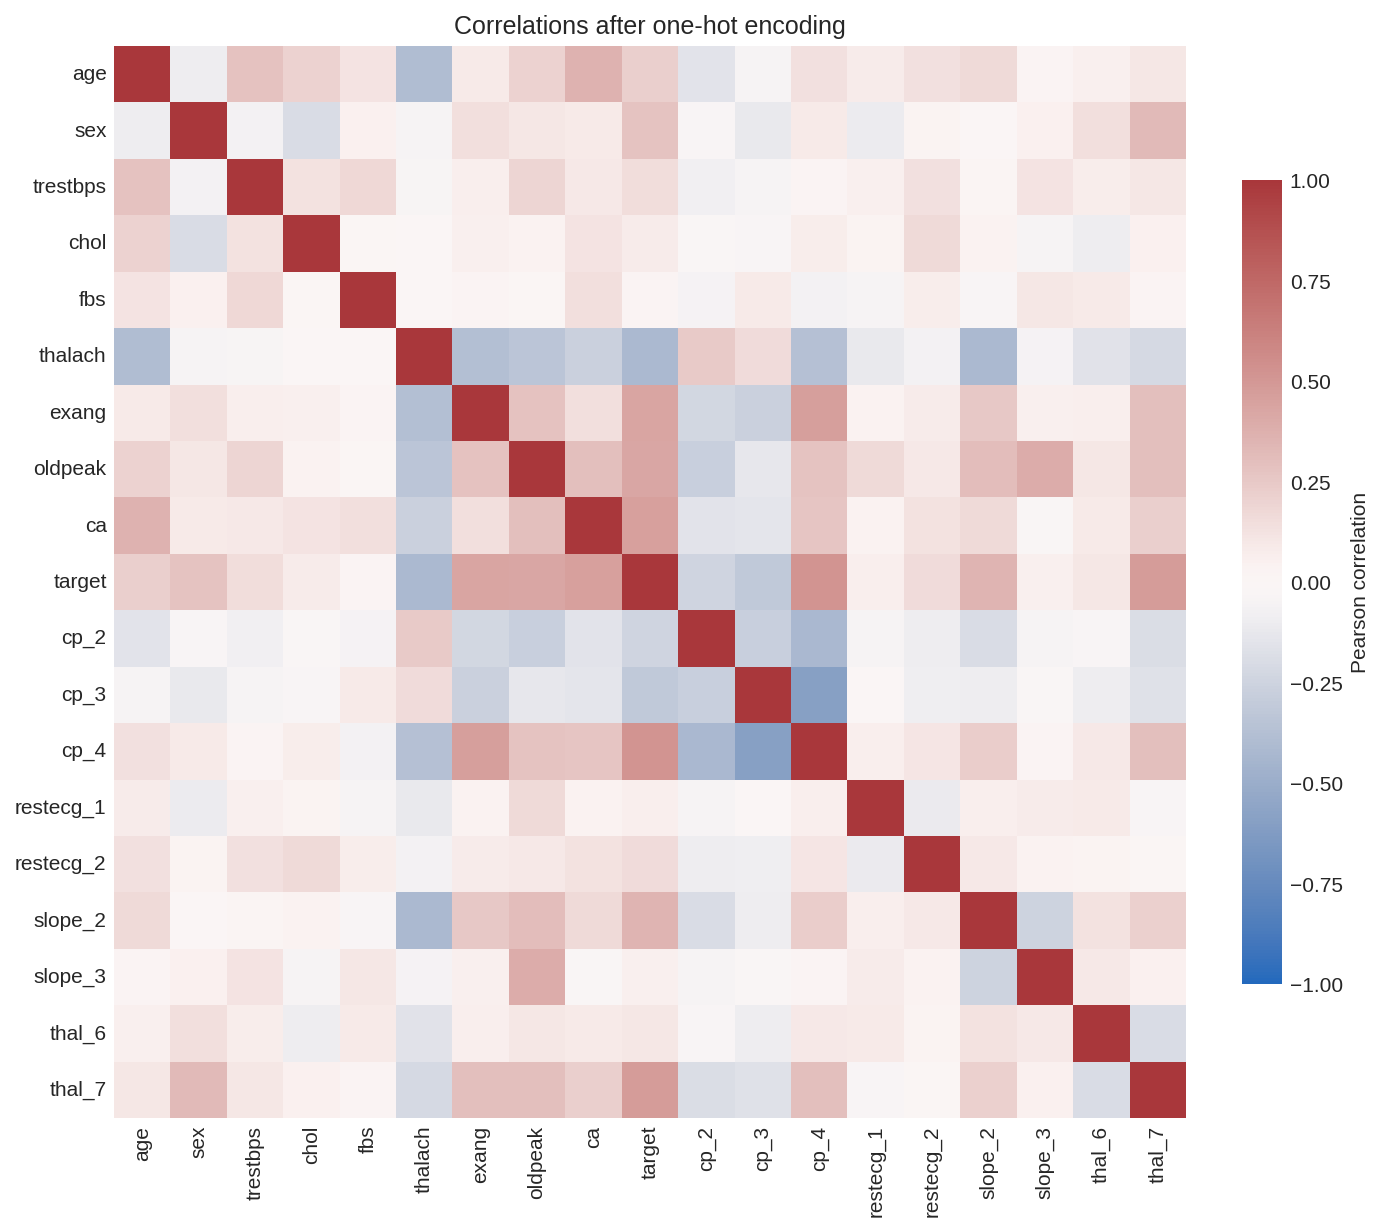

,Correlation with target
cp_4,0.516
thal_7,0.481
ca,0.460
exang,0.432
oldpeak,0.425
thalach,-0.417
slope_2,0.356
cp_3,-0.315


In [8]:
correlations = df_encoded.corr()
fig, ax = plt.subplots(figsize=(9.2, 8.1), layout="constrained")
sns.heatmap(correlations, cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.75}, ax=ax)
ax.set_title("Correlations after one-hot encoding")
plt.show()
target_correlations = correlations.target.drop("target").sort_values(key=abs, ascending=False)
display(target_correlations.head(8).round(3).rename("Correlation with target").to_frame())

The strongest absolute correlations with the outcome are `cp_4` (+0.516), `thal_7` (+0.481), `ca` (+0.460), `exang` (+0.432), `oldpeak` (+0.425), and `thalach` (−0.417). These are pairwise associations in this sample.

## 3. Prepare train and test data

Use a stratified 80/20 split with seed 42. Rebuild the predictor matrices from the corresponding raw rows so the full-data EDA imputation does not enter the model. Fit both the imputation modes and the scaler on the training set.

In [9]:
X = df_encoded.drop(columns="target")
y = df_encoded.target
train_index, test_index = train_test_split(X.index, test_size=0.2, stratify=y, random_state=42)
X_train_raw = df.drop(columns="target").loc[train_index]
X_test_raw = df.drop(columns="target").loc[test_index]
y_train, y_test = y.loc[train_index], y.loc[test_index]

training_modes = X_train_raw[affected].mode().iloc[0]
X_train = encode_features(X_train_raw.fillna(training_modes))
X_test = encode_features(X_test_raw.fillna(training_modes))
assert X.columns.equals(X_train.columns) and X_train.columns.equals(X_test.columns)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {len(y_train)} rows | Test: {len(y_test)} rows | Encoded predictors: {X.shape[1]}")
print("Training modes:", training_modes.astype(int).to_dict())
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).sort_index())

Train: 242 rows | Test: 61 rows | Encoded predictors: 18
Training modes: {'ca': 0, 'thal': 3}


,Train,Test
target,,
0,131,33
1,111,28


## 4. Train and evaluate logistic regression

In [10]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
coefficients = pd.DataFrame({"Feature": X_train.columns, "Coefficient": model.coef_[0]})
display(coefficients.sort_values("Coefficient", ascending=False, ignore_index=True).round(4))

,Feature,Coefficient
0,ca,1.1530
1,cp_4,0.8699
2,sex,0.7371
3,thal_7,0.6809
4,slope_2,0.5986
5,trestbps,0.3537
6,cp_2,0.3402
7,exang,0.2729
8,chol,0.2014
9,restecg_2,0.1989


`ca`, `cp_4`, `sex`, and `thal_7` have the largest positive coefficients. `thalach` has the most negative coefficient. Each coefficient describes a conditional association with the modeled log-odds per training standard deviation of that input. For a standardized dummy variable, that is different from the effect of switching the category from 0 to 1.

Test accuracy: 0.8197
                 precision    recall  f1-score   support

     No disease      0.844     0.818     0.831        33
Disease present      0.793     0.821     0.807        28

       accuracy                          0.820        61
      macro avg      0.818     0.820     0.819        61
   weighted avg      0.821     0.820     0.820        61



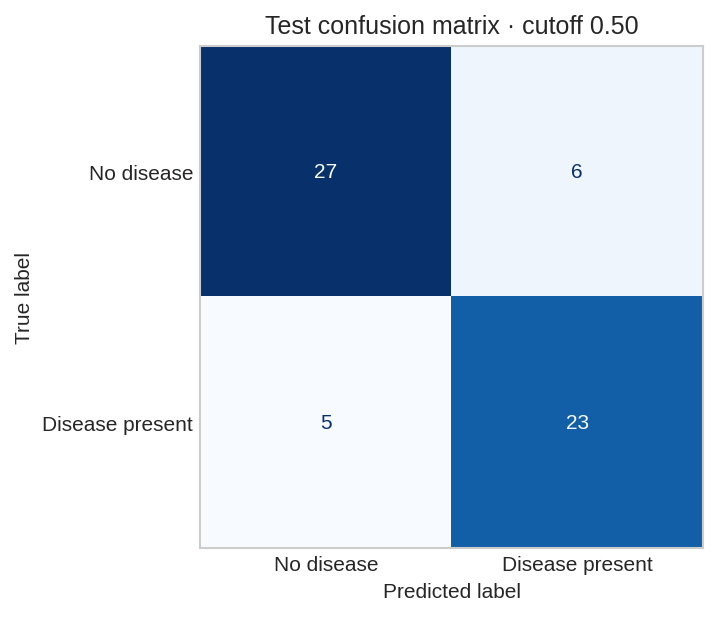

In [11]:
class_names = ["No disease", "Disease present"]
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

default_cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=class_names,
                            digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(5.5, 4), layout="constrained")
ConfusionMatrixDisplay(default_cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Test confusion matrix · cutoff 0.50")
ax.grid(False)
plt.show()

Test ROC AUC: 0.9394


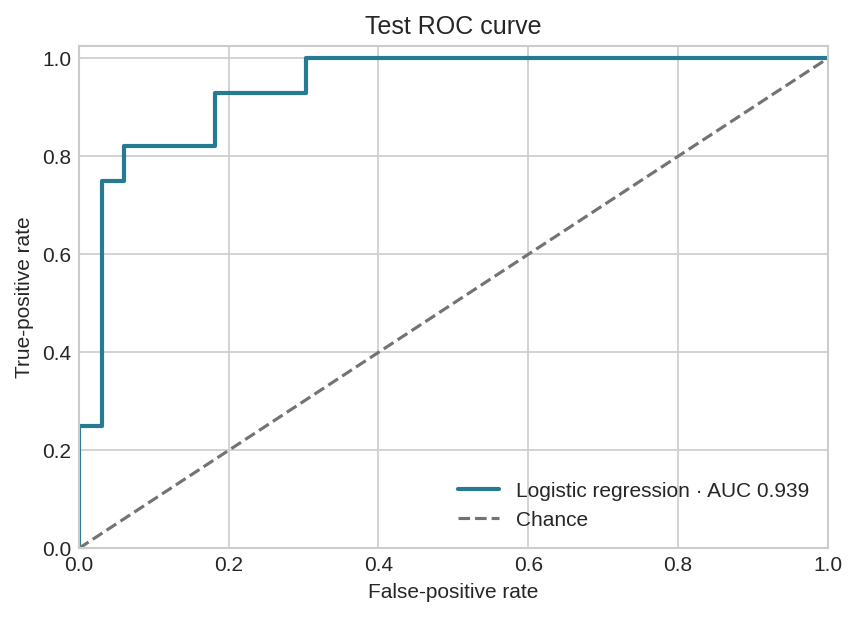

In [12]:
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
print(f"Test ROC AUC: {auc:.4f}")
fig, ax = plt.subplots(figsize=(5.6, 4), layout="constrained")
ax.plot(fpr, tpr, color="#267a92", linewidth=2, label=f"Logistic regression · AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="0.45", label="Chance")
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Test ROC curve",
       xlim=(0, 1), ylim=(0, 1.025))
ax.legend(loc="lower right")
plt.show()

## 5. Select and evaluate an alert cutoff

For the lab's hypothetical 5:1 cost ratio, the expected loss of referring is `1 × (1 − p)`; the expected loss of withholding an alert is `5 × p`. Equating these losses gives a cutoff of `1/6` when the model score can be treated as a calibrated probability and these are the only costs. The cutoff is set from the supplied ratio before comparing results on the test set. Calibration is unverified in this exercise.

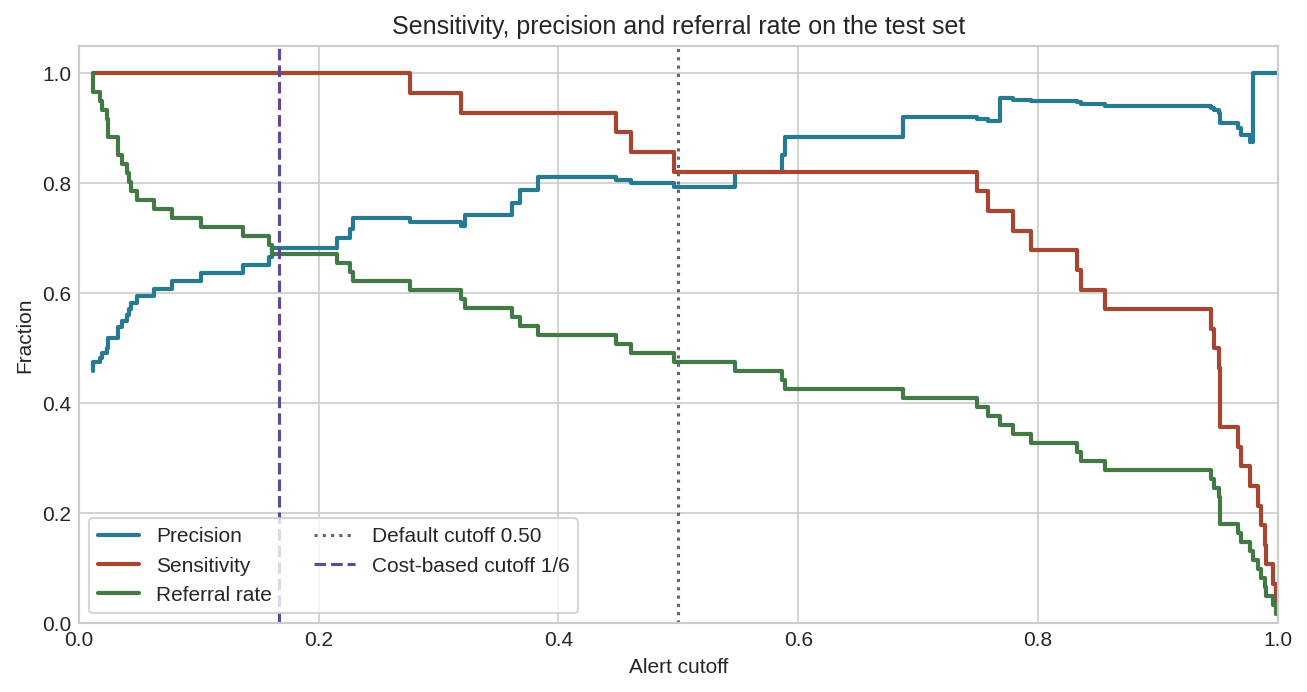

In [13]:
my_threshold = 1 / (5 + 1)
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)
referral_rates = np.array([(y_pred_proba >= t).mean() for t in pr_thresholds])

fig, ax = plt.subplots(figsize=(8.6, 4.5), layout="constrained")
ax.step(pr_thresholds, precisions[:-1], where="pre", label="Precision", color="#267a92", linewidth=2)
ax.step(pr_thresholds, recalls[:-1], where="pre", label="Sensitivity", color="#a64530", linewidth=2)
ax.step(pr_thresholds, referral_rates, where="pre", label="Referral rate", color="#427944", linewidth=2)
ax.axvline(0.5, color="0.40", linestyle=":", label="Default cutoff 0.50")
ax.axvline(my_threshold, color="#5f4799", linestyle="--", label="Cost-based cutoff 1/6")
ax.set(xlabel="Alert cutoff", ylabel="Fraction", title="Sensitivity, precision and referral rate on the test set",
       xlim=(0, 1), ylim=(0, 1.05))
ax.legend(loc="lower left", ncol=2, frameon=True)
plt.show()

In [14]:
y_pred_custom = (y_pred_proba >= my_threshold).astype(int)
custom_cm = confusion_matrix(y_test, y_pred_custom, labels=[0, 1])
print(f"Cost-based cutoff: {my_threshold:.6f}")
display(pd.DataFrame(custom_cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))
print(classification_report(y_test, y_pred_custom, labels=[0, 1], target_names=class_names,
                            digits=3, zero_division=0))

comparison_rows = []
for threshold, matrix in [(0.5, default_cm), (my_threshold, custom_cm)]:
    tn, fp, fn, tp = matrix.ravel()
    total = matrix.sum()
    comparison_rows.append({
        "Cutoff": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": (tn + tp) / total, "Sensitivity": tp / (tp + fn),
        "Precision": tp / (tp + fp), "Referral rate": (tp + fp) / total,
        "Weighted error": 5 * fn + fp,
    })
threshold_comparison = pd.DataFrame(comparison_rows)
display(threshold_comparison.round(4))

Cost-based cutoff: 0.166667


,Predicted 0,Predicted 1
Actual 0,20,13
Actual 1,0,28


                 precision    recall  f1-score   support

     No disease      1.000     0.606     0.755        33
Disease present      0.683     1.000     0.812        28

       accuracy                          0.787        61
      macro avg      0.841     0.803     0.783        61
   weighted avg      0.854     0.787     0.781        61



,Cutoff,TN,FP,FN,TP,Accuracy,Sensitivity,Precision,Referral rate,Weighted error
0,0.5000,27,6,5,23,0.8197,0.8214,0.7931,0.4754,31
1,0.1667,20,13,0,28,0.7869,1.0000,0.6829,0.6721,13


### Cutoff justification

I chose **1/6 (about 0.167)** using the lab's assumption that one missed case costs the same as five unnecessary referrals. On the 61-patient test set, sensitivity rose from **82.14% to 100%**, while the referral rate rose from **47.54% to 67.21%**. The lower cutoff caught five additional cases and generated seven additional false positives, reducing the weighted error from 31 to 13. I would tell the clinic that this is a trade-off observed in one small test set and that the cutoff and referral volume need checking on local data.

## 6. Score the three example patients

These are the same profiles supplied in the lab, written with their original category codes so they pass through the same encoder and scaler as the training data.

In [15]:
sample_patients = pd.DataFrame(
    [
        [62, 1, 4, 152, 275, 0, 2, 118, 1, 2.4, 2, 2, 7],
        [41, 0, 2, 118, 190, 0, 0, 172, 0, 0.2, 1, 0, 3],
        [55, 1, 3, 130, 233, 1, 0, 150, 0, 1.0, 2, 0, 3],
    ],
    columns=columns[:-1],
    index=pd.Index(["A", "B", "C"], name="Patient"),
)
sample_encoded = encode_features(sample_patients)[X.columns]
sample_probs = model.predict_proba(scaler.transform(sample_encoded))[:, 1]
default_alert = sample_probs >= 0.5
custom_alert = sample_probs >= my_threshold
results = pd.DataFrame({
    "Predicted Probability": sample_probs,
    "Alert at 0.5 (default)": np.where(default_alert, "Refer", "No alert"),
    "Alert at 1/6 (chosen)": np.where(custom_alert, "Refer", "No alert"),
}, index=sample_patients.index)
display(results.round(4).reset_index())
changed = results.index[default_alert != custom_alert].tolist()
print("Patients whose alert changed:", ", ".join(changed) if changed else "None")

,Patient,Predicted Probability,Alert at 0.5 (default),Alert at 1/6 (chosen)
0,A,0.9981,Refer,Refer
1,B,0.0118,No alert,No alert
2,C,0.1343,No alert,No alert


Patients whose alert changed: None


A triggers an alert at both cutoffs, and B and C trigger neither. C's score of about 0.134 is below the chosen cutoff. The profiles did not change even though 12 patients in the test set were newly flagged. A change requires a score at least 1/6 and below 0.50.

## 7. Discussion answers

### 1. When would alert fatigue become a concern?

I would look for sustained referral volume above what the clinic can handle, rising overrides of actionable alerts, longer response times, or an increase in alerts that receive no follow-up. The 67.21% flag rate on this test set is a prompt to estimate local workload and test how clinicians respond. The concern is whether frequent alerts cause staff to overlook the ones that need action. [AHRQ PSNet, Alert Fatigue](https://psnet.ahrq.gov/primer/alert-fatigue)

### 2. Who should decide the threshold?

A clinical guidelines or governance committee should own the policy. Treating clinicians can explain how missed cases and unnecessary referrals affect care, administrators can estimate capacity, and developers can present validation results, uncertainty and the effects of candidate cutoffs. The treating clinician remains responsible for applying the alert to the individual patient's circumstances and can document an override.

### 3. What might go wrong at a hospital in another country?

This exercise fits 242 of 303 historical records from Cleveland. A new hospital may differ in disease prevalence, case mix, testing protocols, and which patients receive angiography. A score could overestimate or underestimate risk, and the same cutoff could miss more cases in some groups or overwhelm referral capacity. Local external validation should assess calibration, sensitivity, precision, referral rate, and subgroup performance using predictors available at the actual referral decision. [BMJ, How to undertake an external validation study](https://www.bmj.com/content/384/bmj-2023-074820)

### 4. What should the interface show alongside the alert?

Show the score and cutoff, the factors that contributed most for this patient, and the inputs the tool used, including missing or stale values. Indicate how well the model was validated for patients in this setting and whether the score has been calibrated. Use plain-language descriptions of how each factor influenced the score, with an option to review the supporting data or record an override. [FDA, Reviewing the basis of a clinical decision support recommendation](https://www.fda.gov/medical-devices/digital-health-center-excellence/step-6-software-function-intended-provide-clinical-decision-support)

## 8. Conclusion

The model ranked cases well in this split. Lowering the cutoff changed who would be referred and increased the number of false positives. Applying a policy like this in practice would require validation at the intended decision point, with particular attention to pre-referral predictor availability and local calibration.

In [16]:
assert len(y_train) == 242 and len(y_test) == 61
assert set(train_index).isdisjoint(test_index)
assert default_cm.tolist() == [[27, 6], [5, 23]]
assert custom_cm.tolist() == [[20, 13], [0, 28]]
assert np.isclose(auc, 0.9393939394)
assert changed == []
print("All lab checks passed.")

All lab checks passed.
